# Show Phase: Foto Awal → Onset → Apex → Offset

Format:
- Baris 1: foto awal
- Baris 2: onset, apex, offset

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
EVENT_DIR = ROOT / 'output/frames_per_q/anxiety-tinggi_muhammad_khalid_atthoriq_1765181327851_q1'
SAVE_DIR = ROOT / 'output/apex/visual_examples'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

def natural_sort_key(path: Path):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', path.name)]

frames = sorted(
    [p for p in EVENT_DIR.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}],
    key=natural_sort_key,
)

if len(frames) < 4:
    raise ValueError(f'Butuh minimal 4 frame: {EVENT_DIR}')

n = len(frames)
idx_awal = 0
idx_onset = max(1, int(n * 0.30))
idx_apex = max(2, int(n * 0.50))
idx_offset = max(3, int(n * 0.70))

print('event:', EVENT_DIR.relative_to(ROOT))
print('total frame:', n)
print('awal:', idx_awal, frames[idx_awal].name)
print('onset:', idx_onset, frames[idx_onset].name)
print('apex:', idx_apex, frames[idx_apex].name)
print('offset:', idx_offset, frames[idx_offset].name)


event: output/frames_per_q/anxiety-tinggi_muhammad_khalid_atthoriq_1765181327851_q1
total frame: 386
awal: 0 frame_00000.jpg
onset: 115 frame_00115.jpg
apex: 193 frame_00193.jpg
offset: 270 frame_00270.jpg


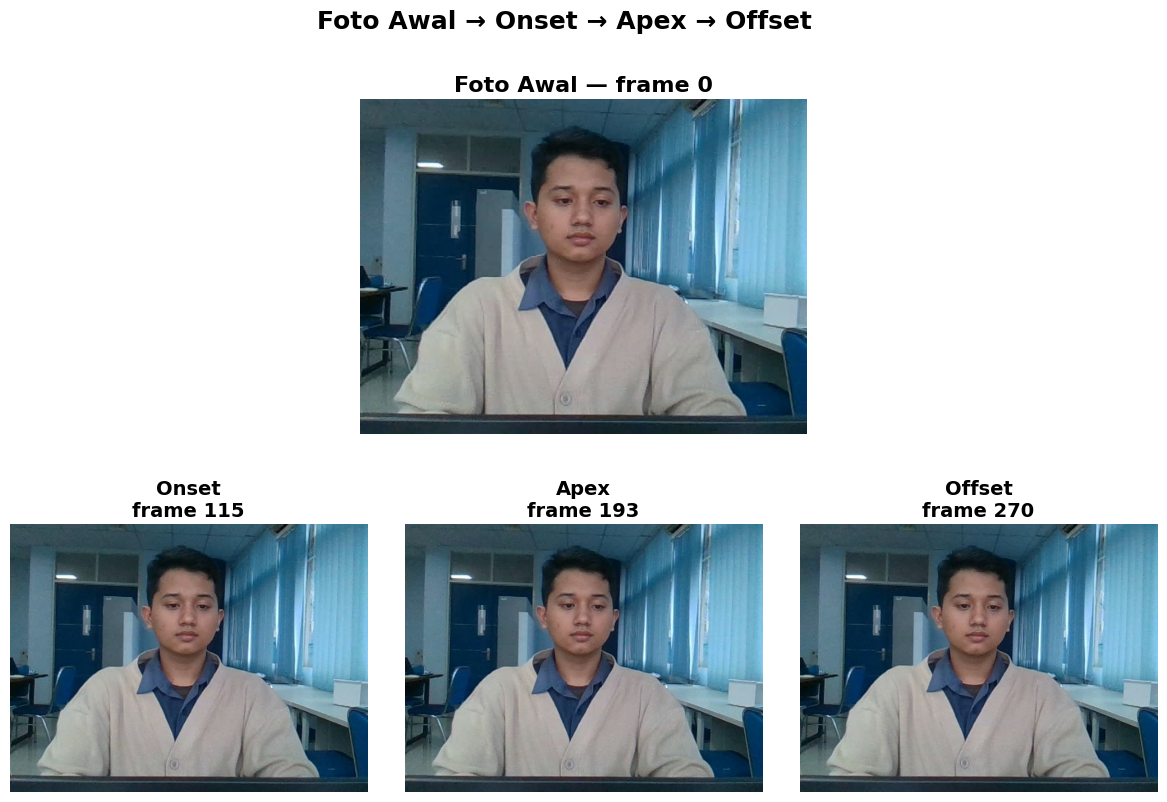

saved: output/apex/visual_examples/show_phase_khalid.png


In [2]:
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1], hspace=0.30, wspace=0.06)

ax_awal = fig.add_subplot(gs[0, :])
ax_awal.imshow(Image.open(frames[idx_awal]))
ax_awal.set_title(f'Foto Awal — frame {idx_awal}', fontsize=16, fontweight='bold')
ax_awal.axis('off')

phase_items = [
    ('Onset', idx_onset),
    ('Apex', idx_apex),
    ('Offset', idx_offset),
]

for col, (label, idx) in enumerate(phase_items):
    ax = fig.add_subplot(gs[1, col])
    ax.imshow(Image.open(frames[idx]))
    ax.set_title(f'{label}\nframe {idx}', fontsize=14, fontweight='bold')
    ax.axis('off')

fig.suptitle('Foto Awal → Onset → Apex → Offset', fontsize=18, fontweight='bold')
save_path = SAVE_DIR / 'show_phase_khalid.png'
fig.savefig(save_path, dpi=220, bbox_inches='tight')
plt.show()
print('saved:', save_path.relative_to(ROOT))
